# 01 · Data Merge, Cleaning & EDA (Member 4)

**Goal:** turn `customer_transactions.csv` and `customer_social_profiles.csv` into one clean table
(one row per transaction) that the product recommendation model can learn from.

Steps: **profile → clean → aggregate social data → merge → validate the merge → EDA → feature engineering → save**.

The same logic lives in `scripts/data_merge.py`, so the merged file can be rebuilt from the command line
(`python scripts/data_merge.py`) without opening this notebook.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Works whether the notebook is started from the repo root or from notebooks/
ROOT = Path.cwd() if (Path.cwd() / "data" / "raw").exists() else Path.cwd().parent
RAW, PROCESSED = ROOT / "data" / "raw", ROOT / "data" / "processed"
TARGET = "product_category"
sns.set_style("whitegrid")
pd.set_option("display.width", 140)

social = pd.read_csv(RAW / "customer_social_profiles.csv")
trans = pd.read_csv(RAW / "customer_transactions.csv")
print("social:", social.shape, "  transactions:", trans.shape)

social: (155, 5)   transactions: (150, 6)


## 1. Profile the raw data
Variable types, missing values and duplicates for each source before touching anything.

In [2]:
def profile(name, df):
    out = pd.DataFrame({"dtype": df.dtypes.astype(str),
                        "nulls": df.isna().sum(),
                        "unique": df.nunique()})
    print(f"=== {name}: {df.shape[0]} rows x {df.shape[1]} cols, "
          f"{df.duplicated().sum()} exact duplicate rows")
    return out

profile("customer_social_profiles", social)

=== customer_social_profiles: 155 rows x 5 cols, 5 exact duplicate rows


,dtype,nulls,unique
customer_id_new,str,0,84
social_media_platform,str,0,5
engagement_score,int64,0,50
purchase_interest_score,float64,0,40
review_sentiment,str,0,3


In [3]:
profile("customer_transactions", trans)

=== customer_transactions: 150 rows x 6 cols, 0 exact duplicate rows


,dtype,nulls,unique
customer_id_legacy,int64,0,75
transaction_id,int64,0,150
purchase_amount,int64,0,120
purchase_date,str,0,150
product_category,str,0,5
customer_rating,float64,10,37


In [4]:
print("social sample:"); print(social.head(3).to_string(index=False))
print("\ntransactions sample:"); print(trans.head(3).to_string(index=False))

social sample:
customer_id_new social_media_platform  engagement_score  purchase_interest_score review_sentiment
           A178              LinkedIn                74                      4.9         Positive
           A190               Twitter                82                      4.8          Neutral
           A150              Facebook                96                      1.6         Positive

transactions sample:
 customer_id_legacy  transaction_id  purchase_amount purchase_date product_category  customer_rating
                151            1001              408    2024-01-01           Sports              2.3
                192            1002              332    2024-01-02      Electronics              4.2
                114            1003              442    2024-01-03      Electronics              2.1


**What the profile shows**

| Issue | Where | Fix |
|---|---|---|
| Customer IDs use different formats (`A178` vs `178`) | both | strip the `A` and cast to `int`, so the keys match |
| 5 exact duplicate rows | social | drop them; they are the same record entered twice |
| 10 missing `customer_rating` | transactions | fill with the median (3.0) |
| `purchase_date` stored as text | transactions | convert to `datetime` |
| Several social rows per customer | social | aggregate to one row per customer before joining |

## 2. Clean

In [5]:
# Exact duplicates in the social table
dups = social[social.duplicated(keep=False)].sort_values("customer_id_new")
print(f"{social.duplicated().sum()} exact duplicates (each shown with its copy):")
print(dups.to_string(index=False))

5 exact duplicates (each shown with its copy):
customer_id_new social_media_platform  engagement_score  purchase_interest_score review_sentiment
           A116               Twitter                78                      1.1         Negative
           A116               Twitter                78                      1.1         Negative
           A125              LinkedIn                66                      4.7         Positive
           A125              LinkedIn                66                      4.7         Positive
           A155                TikTok                98                      4.8         Positive
           A155                TikTok                98                      4.8         Positive
           A162               Twitter                71                      4.8         Positive
           A162               Twitter                71                      4.8         Positive
           A189               Twitter                59                

In [6]:
# ID format check before converting, so a malformed ID fails loudly instead of silently
assert social["customer_id_new"].str.fullmatch(r"A\d+").all()

social = social.drop_duplicates().copy()
social["customer_id"] = social["customer_id_new"].str[1:].astype(int)

assert trans["transaction_id"].is_unique
trans["customer_id"] = trans["customer_id_legacy"].astype(int)
trans["purchase_date"] = pd.to_datetime(trans["purchase_date"], format="%Y-%m-%d")

median_rating = trans["customer_rating"].median()
print("transactions with a missing rating:", trans.loc[trans["customer_rating"].isna(), "transaction_id"].tolist())
trans["customer_rating"] = trans["customer_rating"].fillna(median_rating)
print(f"filled with median = {median_rating}")

# Range checks: every value must be inside its documented scale
checks = {
    "purchase_amount > 0": (trans["purchase_amount"] > 0).all(),
    "customer_rating in [1, 5]": trans["customer_rating"].between(1, 5).all(),
    "engagement_score in [0, 100]": social["engagement_score"].between(0, 100).all(),
    "purchase_interest_score in [1, 5]": social["purchase_interest_score"].between(1, 5).all(),
}
for k, v in checks.items():
    print(f"[{'PASS' if v else 'FAIL'}] {k}")
print("\nsocial rows:", len(social), "| nulls left:", int(social.isna().sum().sum() + trans.isna().sum().sum()))

transactions with a missing rating: [1039, 1042, 1043, 1070, 1081, 1089, 1098, 1101, 1110, 1143]
filled with median = 3.0
[PASS] purchase_amount > 0
[PASS] customer_rating in [1, 5]
[PASS] engagement_score in [0, 100]
[PASS] purchase_interest_score in [1, 5]

social rows: 150 | nulls left: 0


The **median** is used for the rating because it is not pulled by extreme values and keeps the filled values
on the 1–5 scale. Only 10 of 150 rows (6.7%) are affected, so the distribution barely changes.

## 3. Join logic

The social table has **several rows per customer** (one per platform, sometimes repeated on the same
platform). Joining it straight onto the transactions would copy each transaction once per profile and
inflate the dataset, so each customer's profiles are first summarised into **one row**.

In [7]:
per_customer = social.groupby("customer_id").size()
print("social rows per customer:", per_customer.value_counts().sort_index().to_dict())
print("same customer + same platform repeated:", social.duplicated(["customer_id", "social_media_platform"]).sum())

def mode_first(s):
    # most frequent value; ties broken alphabetically so the result is reproducible
    return s.mode().iloc[0]

social_agg = social.groupby("customer_id").agg(
    avg_engagement=("engagement_score", "mean"),
    avg_purchase_interest=("purchase_interest_score", "mean"),
    n_social_profiles=("social_media_platform", "count"),
    top_platform=("social_media_platform", mode_first),
    top_sentiment=("review_sentiment", mode_first),
).reset_index()
social_agg.head()

social rows per customer: {1: 43, 2: 23, 3: 13, 4: 4, 6: 1}
same customer + same platform repeated: 19


,customer_id,avg_engagement,avg_purchase_interest,n_social_profiles,top_platform,top_sentiment
0,100,77.000000,4.400000,2,Instagram,Negative
1,101,68.000000,1.000000,1,Twitter,Neutral
2,102,51.000000,4.800000,1,LinkedIn,Neutral
3,103,64.333333,2.866667,3,Instagram,Positive
4,104,83.000000,2.933333,3,Twitter,Negative


In [8]:
t_ids, s_ids = set(trans["customer_id"]), set(social_agg["customer_id"])
print(f"customers in transactions: {len(t_ids)}")
print(f"customers in social data:  {len(s_ids)}")
print(f"in both:                   {len(t_ids & s_ids)}")
print(f"transactions only:         {len(t_ids - s_ids)}  -> kept, social features imputed")
print(f"social only:               {len(s_ids - t_ids)}  -> dropped, they have no purchase to learn from")

customers in transactions: 75
customers in social data:  84
in both:                   61
transactions only:         14  -> kept, social features imputed
social only:               23  -> dropped, they have no purchase to learn from


**Why a LEFT join on `customer_id`:** the target (`product_category`) only exists in the transactions,
so every transaction must survive the merge. Social-only customers have no label, so the model cannot
use them. `validate="m:1"` makes pandas raise an error if the social side ever has more than one row per
customer, which guarantees no row duplication.

In [9]:
merged = trans.merge(social_agg, on="customer_id", how="left", validate="m:1", indicator=True)
print(merged["_merge"].value_counts())
print("\nnulls created by the join:")
print(merged.isna().sum()[lambda s: s > 0])

_merge
both          117
left_only      33
right_only      0
Name: count, dtype: int64

nulls created by the join:
avg_engagement           33
avg_purchase_interest    33
n_social_profiles        33
top_platform             33
top_sentiment            33
dtype: int64


In [10]:
# Transactions without a social profile: median scores, 0 profiles, explicit "Unknown" category
num = ["avg_engagement", "avg_purchase_interest"]
merged[num] = merged[num].fillna(merged[num].median())
merged["n_social_profiles"] = merged["n_social_profiles"].fillna(0)
merged[["top_platform", "top_sentiment"]] = merged[["top_platform", "top_sentiment"]].fillna("Unknown")
merged = merged.drop(columns="_merge")
print("nulls left:", int(merged.isna().sum().sum()))

nulls left: 0


## 4. Post-merge validation
Each check compares the merged table back to the cleaned sources.

In [11]:
spot = sorted(t_ids & s_ids)[0]
raw_rows = social[social["customer_id"] == spot]
row = merged[merged["customer_id"] == spot].iloc[0]

post_checks = {
    "row count unchanged (150 in, 150 out)": len(merged) == len(trans),
    "transaction_id still unique": merged["transaction_id"].is_unique,
    "purchase_amount total unchanged": merged["purchase_amount"].sum() == trans["purchase_amount"].sum(),
    "product_category counts unchanged": merged[TARGET].value_counts().equals(trans[TARGET].value_counts()),
    "no nulls left": merged.isna().sum().sum() == 0,
    f"customer {spot}: avg_engagement = mean of its raw rows": np.isclose(row["avg_engagement"], raw_rows["engagement_score"].mean()),
    f"customer {spot}: n_social_profiles = number of raw rows": row["n_social_profiles"] == len(raw_rows),
}
for k, v in post_checks.items():
    print(f"[{'PASS' if v else 'FAIL'}] {k}")
assert all(post_checks.values())
print("\nfinal dtypes:"); print(merged.dtypes.to_string())

[PASS] row count unchanged (150 in, 150 out)
[PASS] transaction_id still unique
[PASS] purchase_amount total unchanged
[PASS] product_category counts unchanged
[PASS] no nulls left
[PASS] customer 100: avg_engagement = mean of its raw rows
[PASS] customer 100: n_social_profiles = number of raw rows

final dtypes:
customer_id_legacy                int64
transaction_id                    int64
purchase_amount                   int64
purchase_date            datetime64[us]
product_category                    str
customer_rating                 float64
customer_id                       int64
avg_engagement                  float64
avg_purchase_interest           float64
n_social_profiles               float64
top_platform                        str
top_sentiment                       str


## 5. Exploratory data analysis
### 5.1 Summary statistics

In [12]:
NUM = ["purchase_amount", "customer_rating", "avg_engagement", "avg_purchase_interest", "n_social_profiles"]
merged[NUM].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
purchase_amount,150.0,280.78,121.33,51.0,179.00,274.00,388.5,495.0
customer_rating,150.0,2.99,1.17,1.0,2.10,3.00,4.0,5.0
avg_engagement,150.0,74.78,11.25,50.0,68.31,77.00,81.0,99.0
avg_purchase_interest,150.0,3.09,0.92,1.0,2.73,3.13,3.6,4.8
n_social_profiles,150.0,1.42,1.09,0.0,1.00,1.00,2.0,4.0


In [13]:
merged[["product_category", "top_platform", "top_sentiment"]].describe()

,product_category,top_platform,top_sentiment
count,150,150,150
unique,5,6,4
top,Sports,Unknown,Positive
freq,35,33,44


### 5.2 Distributions

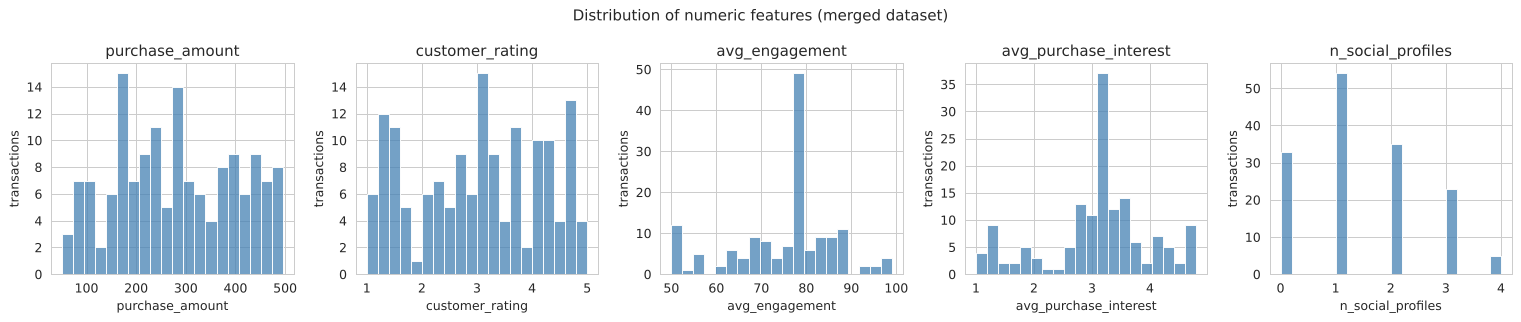

In [14]:
fig, axes = plt.subplots(1, len(NUM), figsize=(17, 3.6))
for ax, c in zip(axes, NUM):
    sns.histplot(merged[c], bins=20, ax=ax, color="steelblue")
    ax.set_title(c); ax.set_xlabel(c); ax.set_ylabel("transactions")
fig.suptitle("Distribution of numeric features (merged dataset)")
fig.tight_layout(); plt.show()

- `purchase_amount` is spread almost uniformly from 51 to 495 (mean 281): no skew, so no transform is needed.
- `customer_rating` covers the full 1–5 scale; the small spike at 3.0 comes from the 10 median-filled values.
- `avg_engagement` and `avg_purchase_interest` have a tall spike at the median: these are the **33 transactions
  with no social profile**, not real behaviour. `n_social_profiles = 0` marks the same rows, so the model can tell them apart.

### 5.3 Outliers

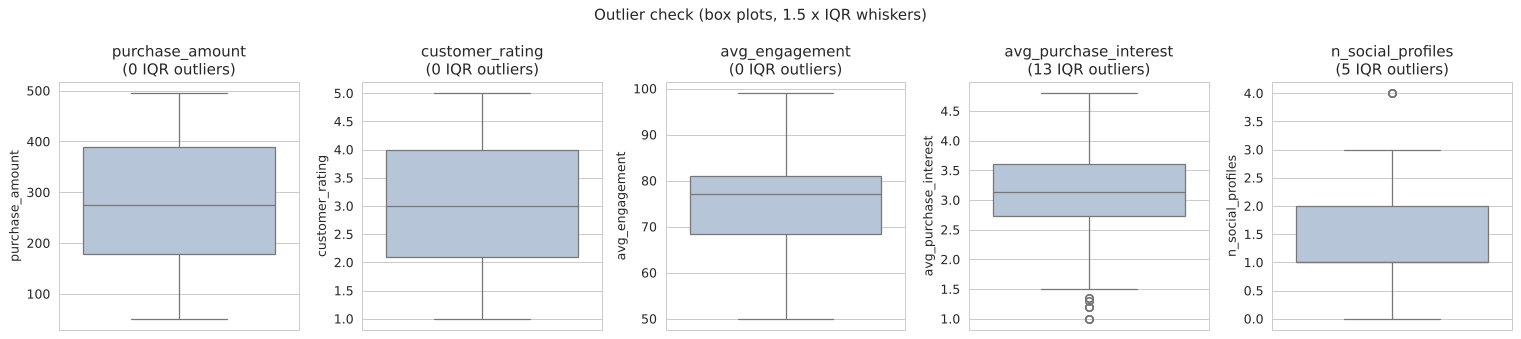

In [15]:
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return int(((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum())

fig, axes = plt.subplots(1, len(NUM), figsize=(17, 3.8))
for ax, c in zip(axes, NUM):
    sns.boxplot(y=merged[c], ax=ax, color="lightsteelblue")
    ax.set_title(f"{c}\n({iqr_outliers(merged[c])} IQR outliers)")
fig.suptitle("Outlier check (box plots, 1.5 x IQR whiskers)")
fig.tight_layout(); plt.show()

- No outliers in `purchase_amount`, `customer_rating` or `avg_engagement`.
- `avg_purchase_interest` flags 13 low values. The median fill makes the box narrow, so ordinary scores of 1.0–1.3
  fall outside the whiskers. They are valid scores on the 1–5 scale and are **kept**.
- `n_social_profiles` flags the customers with 4 profiles: real, just less common. **Kept.**

Nothing was removed: every flagged value is a valid value on its own scale, and with only 150 rows, dropping data would cost more than it gains.

### 5.4 Correlations

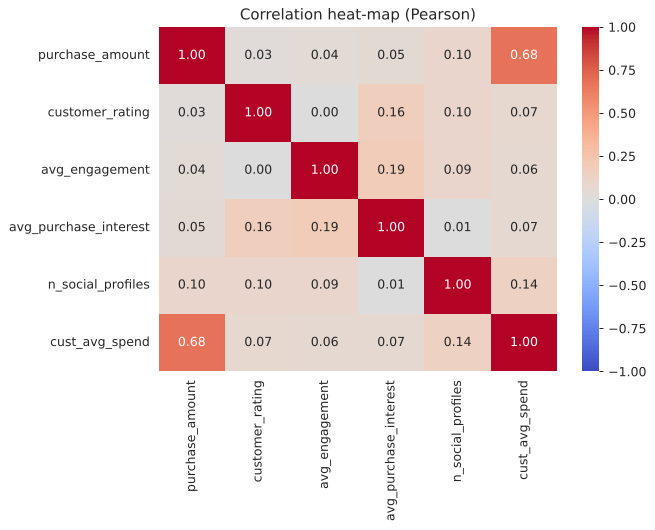

In [16]:
corr_cols = NUM + ["cust_avg_spend"]
tmp = merged.assign(cust_avg_spend=merged.groupby("customer_id")["purchase_amount"].transform("mean"))
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(tmp[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation heat-map (Pearson)")
fig.tight_layout(); plt.show()

All the raw features are only weakly correlated with one another (|r| ≤ 0.19; the largest is between engagement and purchase interest). That means **no multicollinearity**,
but also very little linear signal. The only strong value (0.68) is between `purchase_amount` and the customer's
average spend, which is expected because one is built from the other.

### 5.5 Target and social features

{'Sports': 0.233, 'Electronics': 0.227, 'Clothing': 0.187, 'Groceries': 0.187, 'Books': 0.167}


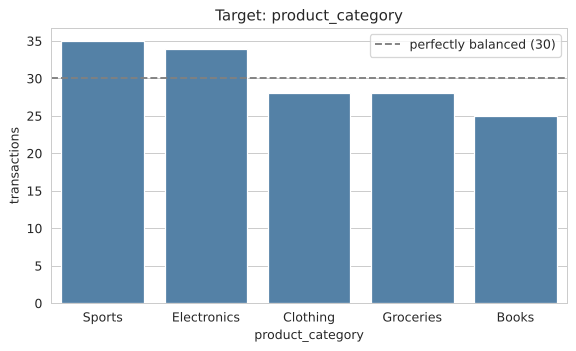

In [17]:
counts = merged[TARGET].value_counts()
fig, ax = plt.subplots(figsize=(6.5, 4))
sns.barplot(x=counts.index, y=counts.values, ax=ax, color="steelblue")
ax.axhline(len(merged) / len(counts), ls="--", c="grey", label="perfectly balanced (30)")
ax.set_title("Target: product_category"); ax.set_ylabel("transactions"); ax.legend()
fig.tight_layout(); plt.show()
print((counts / len(merged)).round(3).to_dict())

The 5 classes are close to balanced: the largest is 23% (Sports) and the smallest is 17% (Books). No resampling is needed,
and accuracy is a fair metric. The baseline is **20% for random guessing** or **23% for always predicting Sports**.

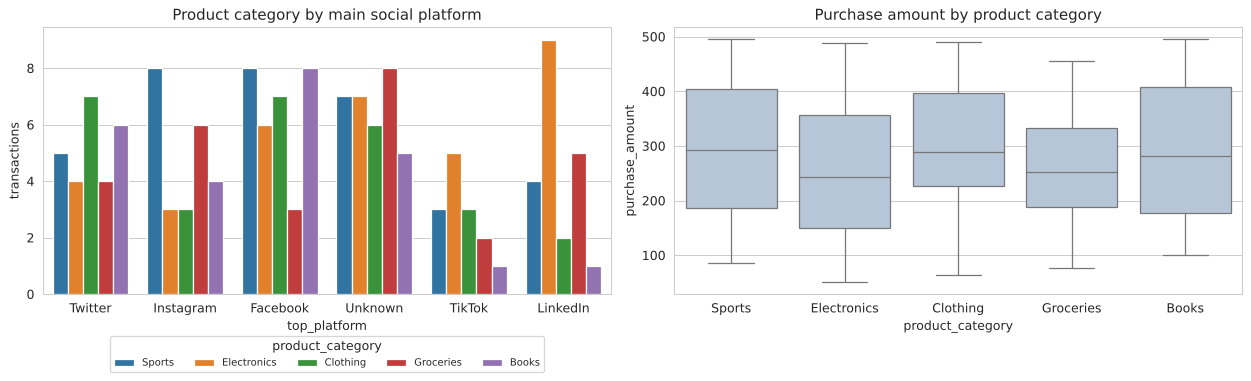

product_category,Books,Clothing,Electronics,Groceries,Sports
top_platform,,,,,
Facebook,8,7,6,3,8
Instagram,4,3,3,6,8
LinkedIn,1,2,9,5,4
TikTok,1,3,5,2,3
Twitter,6,7,4,4,5
Unknown,5,6,7,8,7


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
sns.countplot(data=merged, x="top_platform", hue=TARGET, ax=axes[0])
axes[0].set_title("Product category by main social platform"); axes[0].set_ylabel("transactions")
axes[0].legend(title=TARGET, fontsize=8, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.14))
sns.boxplot(data=merged, x=TARGET, y="purchase_amount", ax=axes[1], color="lightsteelblue")
axes[1].set_title("Purchase amount by product category")
fig.tight_layout(); plt.show()
pd.crosstab(merged["top_platform"], merged[TARGET])

- **Platform carries some signal:** LinkedIn users buy Electronics most often (9 of 21), and Instagram users lean towards
  Sports (8 of 24). The `Unknown` group is spread evenly across all products.
- **Amount barely separates the classes:** the medians run from 243 (Electronics) to 292 (Sports), and the boxes overlap heavily.

**Takeaway for the model:** the signal is weak and spread over several features. A tree ensemble that combines them
should beat any single feature, but we should expect modest accuracy.

## 6. Feature engineering

In [19]:
df = merged.copy()
df["purchase_month"] = df["purchase_date"].dt.month
df["purchase_weekday"] = df["purchase_date"].dt.dayofweek
df["is_weekend"] = (df["purchase_weekday"] >= 5).astype(int)
df["cust_avg_spend"] = df.groupby("customer_id")["purchase_amount"].transform("mean")
df["cust_purchase_count"] = df.groupby("customer_id")["transaction_id"].transform("count")
df["interest_x_engagement"] = df["avg_engagement"] * df["avg_purchase_interest"]
df["high_value_purchase"] = (df["purchase_amount"] > df["purchase_amount"].median()).astype(int)
df[["purchase_month", "purchase_weekday", "is_weekend", "cust_avg_spend",
    "cust_purchase_count", "interest_x_engagement", "high_value_purchase"]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
purchase_month,150.0,2.98,1.42,1.0,2.0,3.00,4.00,5.0
purchase_weekday,150.0,2.96,2.01,0.0,1.0,3.00,5.00,6.0
is_weekend,150.0,0.28,0.45,0.0,0.0,0.00,1.00,1.0
cust_avg_spend,150.0,280.78,82.21,64.0,218.2,272.17,349.00,465.0
cust_purchase_count,150.0,2.61,1.32,1.0,2.0,2.00,3.00,6.0
interest_x_engagement,150.0,232.98,82.05,66.3,193.2,241.27,266.53,417.6
high_value_purchase,150.0,0.49,0.50,0.0,0.0,0.00,1.00,1.0


| Feature | Why |
|---|---|
| `purchase_month`, `purchase_weekday`, `is_weekend` | seasonality and shopping-day habits |
| `cust_avg_spend`, `cust_purchase_count` | a customer's usual budget and loyalty |
| `interest_x_engagement` | an engaged *and* interested customer is a stronger signal than either score alone |
| `high_value_purchase` | marks above-median baskets (> 274) |

## 7. Save

In [20]:
out = PROCESSED / "merged_dataset.csv"
df.to_csv(out, index=False, date_format="%Y-%m-%d")
check = pd.read_csv(out)
print(f"saved {out.relative_to(ROOT)}: {check.shape[0]} rows x {check.shape[1]} columns, "
      f"{int(check.isna().sum().sum())} nulls")

saved data/processed/merged_dataset.csv: 150 rows x 19 columns, 0 nulls


## Summary

- **Cleaning:** removed 5 duplicate social rows, matched the ID formats (`A178` → `178`), filled 10 missing
  ratings with the median, converted the dates.
- **Merge:** summarised the social data to one row per customer (84 customers), then LEFT-joined it on `customer_id`.
  All 150 transactions were kept: 117 matched a social profile and 33 did not.
- **Validation:** 7 post-merge checks pass: same row count, unique IDs, unchanged totals and class counts, no nulls,
  and a spot check against the raw rows.
- **EDA:** the classes are balanced, there are no real outliers and no multicollinearity, and the signal is weak (platform is the clearest one).
- **Output:** `data/processed/merged_dataset.csv` (150 × 19), which Member 1's product model trains on.